# Originación: CUSUM, falsas alarmas y demora

## Resumen de la ejecución

Datos sintéticos; resultados de esta ejecución:

- **Umbral calibrado:** 5.604
- **Falsa alarma en 120 días:** 0.0633
- **Réplicas independientes de evaluación:** 600
- **Escenarios de cambio:** 5

Los supuestos, límites y contraejemplos se explican junto a cada experimento.

## Objetivo y método

¿Qué umbral detecta un cambio sin alertar constantemente? Calibramos el máximo de CUSUM en horizontes de 120 días y evaluamos falsas alarmas en réplicas independientes.

### Supuestos y población

Residuos diarios normales e independientes bajo estabilidad. Se simula un cambio después del día 60. El límite se calibra para una sola serie y un solo horizonte; no controla automáticamente muchos canales ni monitoreo indefinido.

Todos los datos son sintéticos. Las cifras ilustran mecanismos y no constituyen desempeño observado en una entidad. Fecha de desarrollo: 21 de octubre de 2026.

## Entorno reproducible

Ejecutar en orden, desde esta carpeta o una subcarpeta de la línea de fraude. La semilla y los parámetros quedan en las celdas; no se consulta internet ni se leen datos de clientes.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, math, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import average_precision_score, brier_score_loss
base = next(p for p in [Path.cwd(), *Path.cwd().parents] if p.name == 'fraud-and-anomaly-research')
sys.path.insert(0, str(base / 'loss-minimization-engine'))
from src.engine import Case, Action, Scenario, optimize, expected_cost, shared_entity_count
rng = np.random.default_rng(20261021)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'figure.dpi': 120, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False, 'grid.alpha': .25})
BLUE, TEAL, GOLD, PURPLE = '#386A96', '#217A72', '#B37D2E', '#73579D'
pd.options.display.float_format = '{:,.4f}'.format

No event loop hook running.


## 1. Acumular evidencia de un cambio


$$S_t=\max(0,S_{t-1}+z_t-k),\quad \mathrm{alarma}\iff S_t>h.$$

$k$ penaliza pequeñas oscilaciones y $h$ fija tolerancia de evidencia. Un umbral no puede copiarse sin considerar escala, dependencia, número de series y horizonte.

In [2]:
def cusum(z,k=.5):
    result=np.zeros_like(z,dtype=float);state=0.
    for t,value in enumerate(z):
        state=max(0.,state+value-k);result[t]=state
    return result
horizon=120;change_day=60
calibration_paths=rng.normal(size=(600,horizon))
maxima=np.array([cusum(path).max() for path in calibration_paths])
h=float(np.quantile(maxima,.95,method='higher'))
validation_paths=rng.normal(size=(600,horizon))
false_alarm=np.array([cusum(path).max()>h for path in validation_paths])
false_alarm_rate=float(false_alarm.mean())
def wilson(success,n,z=1.96):
    p=success/n;den=1+z*z/n
    center=(p+z*z/(2*n))/den
    radius=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return center-radius,center+radius
ci=wilson(int(false_alarm.sum()),len(false_alarm))
display(pd.DataFrame({'umbral_h':[h],'FA_horizonte_test':[false_alarm_rate],'limite95_inferior':[ci[0]],'limite95_superior':[ci[1]],'replicas':[len(false_alarm)]}))

,umbral_h,FA_horizonte_test,limite95_inferior,limite95_superior,replicas
0,5.6041,0.0633,0.0465,0.0857,600


El intervalo Wilson corresponde a la tasa de réplicas con al menos una alarma en 120 días. No es la tasa diaria ni un intervalo del umbral. Las simulaciones de calibración y validación son diferentes.

## 2. Cambio y causa no son lo mismo


Una subida en omisiones observadas puede provenir de un cambio de proceso o de un cambio en registro. Si producen la misma serie $z_t$, CUSUM devuelve exactamente la misma evidencia: no identifica causalidad ni intención.

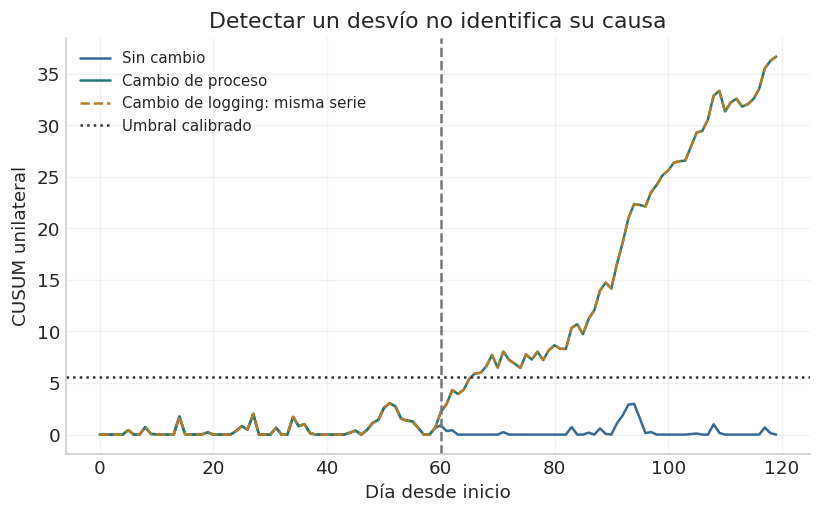

In [3]:
noise=rng.normal(size=horizon)
stable=noise.copy();deviation=noise.copy();deviation[change_day:]+=1.3
logging=deviation.copy()
fig,ax=plt.subplots()
ax.plot(cusum(stable),label='Sin cambio',color=BLUE)
ax.plot(cusum(deviation),label='Cambio de proceso',color=TEAL)
ax.plot(cusum(logging),label='Cambio de logging: misma serie',color=GOLD,linestyle='--')
ax.axhline(h,color='#333333',linestyle=':',label='Umbral calibrado')
ax.axvline(change_day,color='#777777',linestyle='--');ax.set(xlabel='Día desde inicio',ylabel='CUSUM unilateral',title='Detectar un desvío no identifica su causa');ax.legend(fontsize=9);plt.show()

Las dos curvas de cambio coinciden deliberadamente. La explicación necesita bitácora de versión, conciliación de eventos y verificación independiente. El detector estadístico por sí solo no demuestra fraude.

## 3. Tamaño de cambio y tiempo de detección


La primera alarma puede llegar antes del cambio. Se reporta por separado la tasa pre-cambio y la detección dentro del horizonte entre trayectorias sin alarma previa. La mediana de demora usa solo trayectorias detectadas; omite censuradas y se etiqueta así.

,shift,replicas,prealarma,elegibles_sin_prealarma,deteccion_en_elegibles,detectados,mediana_dias_solo_detectados
0,0.3000,400,0.0450,382,0.3455,132,30.0000
1,0.6000,400,0.0275,389,0.8663,337,21.0000
2,1.0000,400,0.0300,388,1.0000,388,10.0000
3,1.5000,400,0.0225,391,1.0000,391,5.0000
4,2.0000,400,0.0300,388,1.0000,388,4.0000


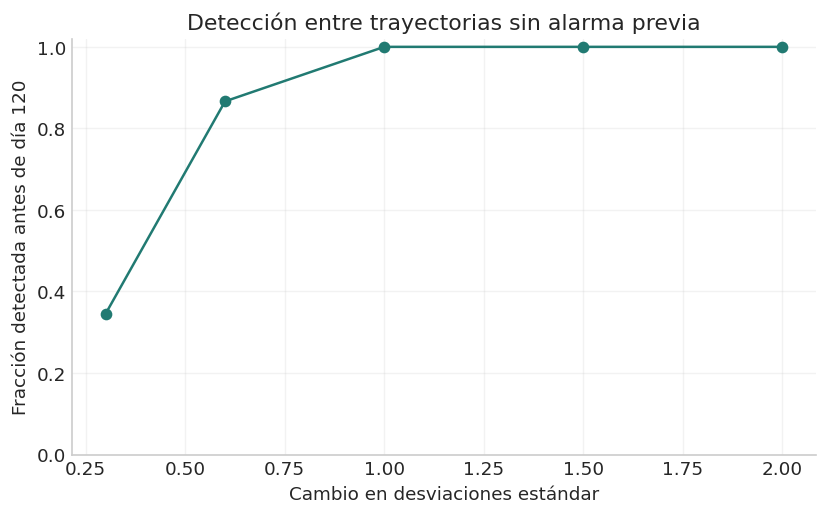

In [4]:
records=[]
for shift in [.3,.6,1.,1.5,2.]:
    paths=rng.normal(size=(400,horizon));paths[:,change_day:]+=shift
    pre_count=0;eligible=0;delays=[]
    for path in paths:
        series=cusum(path);alarms=np.flatnonzero(series>h)
        if len(alarms) and alarms[0]<change_day:pre_count+=1;continue
        eligible+=1
        later=alarms[alarms>=change_day]
        if len(later):delays.append(int(later[0]-change_day+1))
    records.append({'shift':shift,'replicas':400,'prealarma':pre_count/400,'elegibles_sin_prealarma':eligible,
                    'deteccion_en_elegibles':len(delays)/eligible,'detectados':len(delays),
                    'mediana_dias_solo_detectados':float(np.median(delays)) if delays else np.nan})
detection=pd.DataFrame(records);display(detection)
fig,ax=plt.subplots();ax.plot(detection['shift'],detection['deteccion_en_elegibles'],color=TEAL,marker='o')
ax.set(xlabel='Cambio en desviaciones estándar',ylabel='Fracción detectada antes de día 120',ylim=(0,1.02),title='Detección entre trayectorias sin alarma previa');plt.show()

La comparación mantiene h y k congelados y varía solo la simulación de cambio. La tasa pre-cambio y los casos censurados se conservan en la tabla; no se presenta la mediana de detectados como demora poblacional.

## Comprobaciones y límites

Las identidades y contraejemplos siguientes son parte del experimento; no verifican desempeño productivo.

In [5]:
assert np.array_equal(cusum(deviation),cusum(logging))
assert 0<=false_alarm_rate<=1
assert ((detection['detectados']<=detection['elegibles_sin_prealarma'])&(detection['elegibles_sin_prealarma']>0)).all()
assert ci[0]<=false_alarm_rate<=ci[1]

## Resultados computados

In [6]:
metrics = {'Umbral calibrado': round(h,3), 'Falsa alarma en 120 días': round(false_alarm_rate,4), 'Réplicas independientes de evaluación': len(false_alarm), 'Escenarios de cambio': len(detection)}
print("LAB_METRICS:" + json.dumps(metrics, ensure_ascii=False))

LAB_METRICS:{"Umbral calibrado": 5.604, "Falsa alarma en 120 días": 0.0633, "Réplicas independientes de evaluación": 600, "Escenarios de cambio": 5}


## Ideas y preguntas para continuar

1. Introducir residuos autocorrelacionados para probar cuándo se pierde la calibración.
2. Calibrar máximos conjuntos de varios canales, en vez de copiar el umbral de una serie.
3. Comparar reinicios y períodos de espera después de investigar una alarma.
4. Modelar señales de logging y calidad en un canal separado.
5. Incorporar el costo de demora y la capacidad de revisión a la selección de umbral.

## Fuentes y relación con el proyecto

- [NIST: CUSUM](https://www.itl.nist.gov/div898/handbook/pmc/section3/pmc323.htm).
- [NIST: average run length](https://www.itl.nist.gov/div898/handbook/pmc/section3/pmc3131.htm).
Este notebook evalúa probabilidad de alarma a horizonte fijo, no estima ARL infinito.

Consultar también `../README.md` y `../../MODEL_AND_LOSS_METHODS.md`.